In [ ]:
%pip install -q landingai pillow matplotlib gTTS

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Installing backend dependencies ... done
  Preparing metadata (pyproject.toml) ... done
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
spacy 3.8.18 requires click<9.0.0,>=8.2.1, but you have click 8.1.8 which is incompatible.
opencv-contrib-python 4.14.0.94 requires numpy>=2; python_version >= "3.9", but you have numpy 1.26.4 which is incompatible.
jax 0.11.1 requires numpy>=2.1, but you have numpy 1.26.4 which is incompatible.
rasterio 1.5.2 requires numpy>=2, but you have numpy 1.26.4 which is incompatible.
ml-dtypes 0.6.0 requires numpy>=2.0.0, but you have numpy 1.26.4 which is incompatible.
ml-dtypes 0.6.0 requires numpy>=2.1.0; python_version >= "3.13", but you have numpy 1.26.4 which is incompatible.
huggingface-hub 1.33.0 requires click<9.0.0,>=8.4.2, but you have

In [ ]:
%pip install landingai

In [1]:
%pip install pillow==10.4.0

In [2]:
import io
import PIL
from PIL import Image

print("Pillow version:", PIL.__version__)

# Test Pillow's JPEG encoder independently of LandingAI
buffer = io.BytesIO()
test_image = Image.new("RGB", (10, 10), color="red")
test_image.save(buffer, format="JPEG")

print("JPEG encoding successful:", len(buffer.getvalue()), "bytes")

Pillow version: 10.4.0
JPEG encoding successful: 633 bytes


In [6]:
from google.colab import userdata
from landingai.predict import Predictor

API_KEY = userdata.get("LANDINGAI_API_KEY")

ENDPOINT_ID = "34c8db94-54cf-4f14-a1c8-08432086a24b"

predictor = Predictor(
    endpoint_id=ENDPOINT_ID,
    api_key=API_KEY
)

print("LandingAI predictor initialized.")

LandingAI predictor initialized.


In [7]:
from google.colab import files
from PIL import Image
import io
import numpy as np

uploaded = files.upload()
filename = next(iter(uploaded))

with Image.open(io.BytesIO(uploaded[filename])) as im:
    image = im.convert("RGB").copy()

image_array = np.array(image)

print("Image size:", image.size)
print("Image array shape:", image_array.shape)


Saving m11.jpg to m11.jpg
Image size: (600, 600)
Image array shape: (600, 600, 3)


In [8]:
predictions = predictor.predict(image_array)

print("Prediction count:", len(predictions))

for i, prediction in enumerate(predictions, start=1):
    print(f"\nPrediction {i}:")
    print(prediction)


Prediction count: 1

Prediction 1:
score=0.9323743581771851 label_name='Medicine Label' label_index=1 id='16c8f1a6-b51c-490c-b475-3eb8c201b27a' bboxes=(200, 215, 400, 474)


In [9]:
%pip install -q easyocr

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
landingai 0.3.49 requires numpy<2.0.0,>=1.21.0, but you have numpy 2.5.4 which is incompatible.
spacy 3.8.18 requires click<9.0.0,>=8.2.1, but you have click 8.1.8 which is incompatible.
numba 0.64.0 requires numpy<2.5,>=1.22, but you have numpy 2.5.4 which is incompatible.


Progress: |██████████████████████████████████████████████████| 100.0% Complete

Progress: |██████████████████████████████████████████████████| 100.0% CompleteMEDICINE LABEL READING COGNITIVE ASSISTANT
Upload an image of a medicine bottle.


Saving m11.jpg to m11 (1).jpg


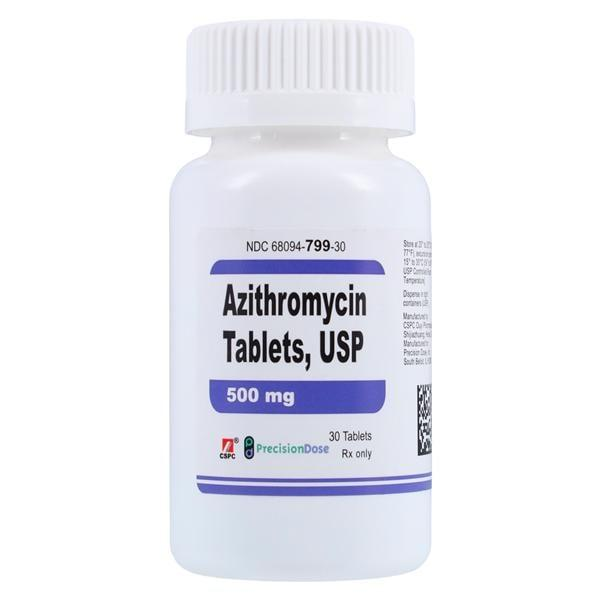


LandingAI Model Predictions:
[ObjectDetectionPrediction(score=0.9323743581771851, label_name='Medicine Label', label_index=1, id='5e9da8d7-d81d-4fc0-8ad0-4f9df552d099', bboxes=(200, 215, 400, 474))]

Extracting text from medicine label...


/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:775: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)



Extracted Medicine Label Information:
NDC 68094-799-30
Azithromycin
Tablets; USP
500 mg
30 Tatlexs
PrecisionDose
Rx only


### Medicine Label Information
NDC 68094-799-30
Azithromycin
Tablets; USP
500 mg
30 Tatlexs
PrecisionDose
Rx only

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [10]:
from google.colab import files
from PIL import Image
from IPython.display import display, Markdown, Audio
from gtts import gTTS
from landingai.predict import Predictor
import easyocr
import numpy as np
import io

# Initialize OCR reader
reader = easyocr.Reader(['en'])


def medicine_label_assistant():

    print("MEDICINE LABEL READING COGNITIVE ASSISTANT")
    print("Upload an image of a medicine bottle.")

    # 1. Upload image
    uploaded = files.upload()

    if not uploaded:
        print("No image uploaded.")
        return

    filename = next(iter(uploaded))

    with Image.open(io.BytesIO(uploaded[filename])) as img:
        image = img.convert("RGB").copy()

    display(image)

    # 2. Run the connected LandingAI model
    predictions = predictor.predict(np.array(image))

    print("\nLandingAI Model Predictions:")
    print(predictions)

    # 3. Perform OCR to extract medicine label text
    print("\nExtracting text from medicine label...")

    results = reader.readtext(np.array(image))

    extracted_text = []

    for detection in results:
        text = detection[1]
        confidence = detection[2]

        if confidence > 0.25:
            extracted_text.append(text)

    # 4. Display extracted information
    if not extracted_text:
        print("No readable text found on the medicine label.")
        return

    medicine_information = "\n".join(extracted_text)

    print("\nExtracted Medicine Label Information:")
    print(medicine_information)

    display(
        Markdown(
            f"### Medicine Label Information\n{medicine_information}"
        )
    )

    # 5. Generate audio response
    speech = gTTS(
        text="The extracted medicine label information is: "
             + medicine_information,
        lang="en"
    )

    speech.save("medicine_information.mp3")

    display(Audio("medicine_information.mp3", autoplay=False))

    files.download("medicine_information.mp3")


# Run the assistant
medicine_label_assistant()